(120, 120) RGB


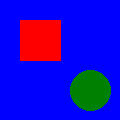

In [1]:
from PIL import Image, ImageDraw
from IPython.display import display

# Crear tu imagen con fondo y al menos 2 figuras[cite: 1]
img = Image.new("RGB", (120, 120), "blue")
draw = ImageDraw.Draw(img)

# figura 1 y 2[cite: 1]
draw.rectangle([20, 20, 60, 60], fill="red")
draw.ellipse([70, 70, 110, 110], fill="green")

print(img.size, img.mode)
img.save("mi_imagen.png")

# Mostrar la imagen original
display(img)

Formato: PNG
1. Escala de grises:


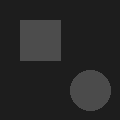

2. Rotada 90 grados:


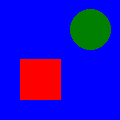

3. Redimensionada a la mitad:


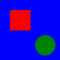

4. Volteada verticalmente:


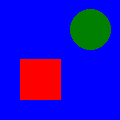

In [2]:
# Reabrir y verificar[cite: 1]
img_reabierta = Image.open("mi_imagen.png")
print("Formato:", img_reabierta.format)

# Las cuatro transformaciones mostrando los resultados[cite: 1]
img_gris = img_reabierta.convert("L")
img_rotada = img_reabierta.rotate(90, expand=True)
img_pequena = img_reabierta.resize((60, 60))
img_volteada = img_reabierta.transpose(Image.FLIP_TOP_BOTTOM)

print("1. Escala de grises:")
display(img_gris)
print("2. Rotada 90 grados:")
display(img_rotada)
print("3. Redimensionada a la mitad:")
display(img_pequena)
print("4. Volteada verticalmente:")
display(img_volteada)

Brillo reducido (0.5):


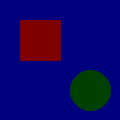

Brillo aumentado (2.5):


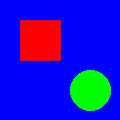

In [3]:
from PIL import ImageEnhance, ImageFilter

# Dos factores de brillo distintos[cite: 1]
enhancer = ImageEnhance.Brightness(img_reabierta)
img_oscuro = enhancer.enhance(0.5)
img_brillo = enhancer.enhance(2.5)

print("Brillo reducido (0.5):")
display(img_oscuro)
print("Brillo aumentado (2.5):")
display(img_brillo)

Filtro Gaussian Blur:


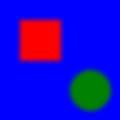

Filtro Find Edges:


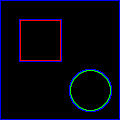

In [4]:
# Aplica y guarda ambos filtros[cite: 1]
img_blur = img_reabierta.filter(ImageFilter.GaussianBlur(radius=2))
img_edges = img_reabierta.filter(ImageFilter.FIND_EDGES)

img_blur.save("blur.png")
img_edges.save("edges.png")

print("Filtro Gaussian Blur:")
display(img_blur)
print("Filtro Find Edges:")
display(img_edges)

Umbral Otsu calculado: 0.0727


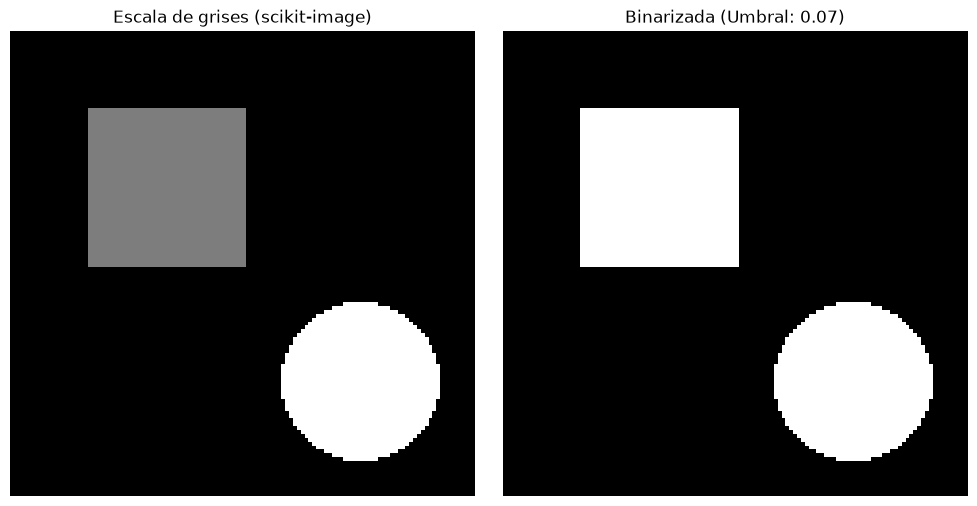

In [6]:
import numpy as np
from skimage import color, filters
import matplotlib.pyplot as plt

# Array y rgb2gray[cite: 1]
img_np = np.array(img_reabierta)
img_gray_sk = color.rgb2gray(img_np)

# threshold_otsu y binarizacion[cite: 1]
umbral_otsu = filters.threshold_otsu(img_gray_sk)
img_binarizada = img_gray_sk > umbral_otsu

print(f"Umbral Otsu calculado: {umbral_otsu:.4f}")

# Mostrar las imágenes procesadas con scikit-image usando matplotlib
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img_gray_sk, cmap='gray')
axes[0].set_title("Escala de grises (scikit-image)")
axes[0].axis('off')

axes[1].imshow(img_binarizada, cmap='gray')
axes[1].set_title(f"Binarizada (Umbral: {umbral_otsu:.2f})")
axes[1].axis('off')

plt.tight_layout()
plt.show()